In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("realestate.csv")
print("Shape:", df.shape)
print("Original columns:", list(df.columns))
df.head()

Shape: (250, 7)
Original columns: ['Property ID', 'Neighborhood ', 'Property-Type', 'Area (sqft)', ' Bedrooms', 'Sale Price (Rs)', 'Year Built']


,Property ID,Neighborhood,Property-Type,Area (sqft),Bedrooms,Sale Price (Rs),Year Built
0,1,Wakad,Villa,604,1,10898035,2020
1,2,Aundh,Villa,2153,3,16490355,2003
2,3,Kothrud,Villa,2912,3,16767181,2021
3,4,Hinjewadi,Flat,1239,2,8590920,1991
4,5,Aundh,Flat,2065,3,17276029,2008


In [3]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("(", "").str.replace(")", "").str.replace("-", "_")
print("Cleaned columns:", list(df.columns))
df.head()

Cleaned columns: ['property_id', 'neighborhood', 'property_type', 'area_sqft', 'bedrooms', 'sale_price_rs', 'year_built']


,property_id,neighborhood,property_type,area_sqft,bedrooms,sale_price_rs,year_built
0,1,Wakad,Villa,604,1,10898035,2020
1,2,Aundh,Villa,2153,3,16490355,2003
2,3,Kothrud,Villa,2912,3,16767181,2021
3,4,Hinjewadi,Flat,1239,2,8590920,1991
4,5,Aundh,Flat,2065,3,17276029,2008


In [4]:
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

property_id      0
neighborhood     0
property_type    0
area_sqft        0
bedrooms         0
sale_price_rs    0
year_built       0
dtype: int64
Total missing values: 0


In [5]:
for col in ["area_sqft", "sale_price_rs"]:
    df[col] = df[col].fillna(df[col].median())
print("Missing values after handling:", df.isnull().sum().sum())

Missing values after handling: 0


In [6]:
neighborhood_info = pd.DataFrame({
    "neighborhood": ["Wakad", "Aundh", "Kothrud", "Hinjewadi"],
    "zone": ["West", "West", "Central", "West"],
    "area_type": ["Residential", "Residential", "Residential", "IT Corridor"]
})
df = pd.merge(df, neighborhood_info, on="neighborhood", how="left")
print("Shape after merging:", df.shape)
df.head()

Shape after merging: (250, 9)


,property_id,neighborhood,property_type,area_sqft,bedrooms,sale_price_rs,year_built,zone,area_type
0,1,Wakad,Villa,604,1,10898035,2020,West,Residential
1,2,Aundh,Villa,2153,3,16490355,2003,West,Residential
2,3,Kothrud,Villa,2912,3,16767181,2021,Central,Residential
3,4,Hinjewadi,Flat,1239,2,8590920,1991,West,IT Corridor
4,5,Aundh,Flat,2065,3,17276029,2008,West,Residential


In [7]:
flats = df[df["property_type"] == "Flat"]
print("Total properties:", len(df))
print("Flats only:", flats.shape)
flats.head()

Total properties: 250
Flats only: (82, 9)


,property_id,neighborhood,property_type,area_sqft,bedrooms,sale_price_rs,year_built,zone,area_type
3,4,Hinjewadi,Flat,1239,2,8590920,1991,West,IT Corridor
4,5,Aundh,Flat,2065,3,17276029,2008,West,Residential
5,6,Aundh,Flat,2892,4,19570342,2015,West,Residential
6,7,Aundh,Flat,2014,2,13812021,2016,West,Residential
8,9,Kothrud,Flat,983,3,7719614,2001,Central,Residential


In [8]:
q1 = df["sale_price_rs"].quantile(0.25)
q3 = df["sale_price_rs"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("Upper limit for sale price:", round(upper, 2))
print("Outlier rows:", int((df["sale_price_rs"] > upper).sum()))
df = df[df["sale_price_rs"] <= upper]
print("Shape after removing outliers:", df.shape)

Upper limit for sale price: 28514656.25
Outlier rows: 0
Shape after removing outliers: (250, 9)


In [9]:
avg_by_neighborhood = df.groupby("neighborhood")["sale_price_rs"].mean().sort_values()
print("Average sale price by neighborhood:")
print(avg_by_neighborhood)
print()
print("Average sale price by property type:")
print(df.groupby("property_type")["sale_price_rs"].mean())

Average sale price by neighborhood:
neighborhood
Kothrud      1.100382e+07
Aundh        1.142568e+07
Wakad        1.151917e+07
Hinjewadi    1.197643e+07
Name: sale_price_rs, dtype: float64

Average sale price by property type:
property_type
Flat     1.214124e+07
Plot     1.136373e+07
Villa    1.091508e+07
Name: sale_price_rs, dtype: float64


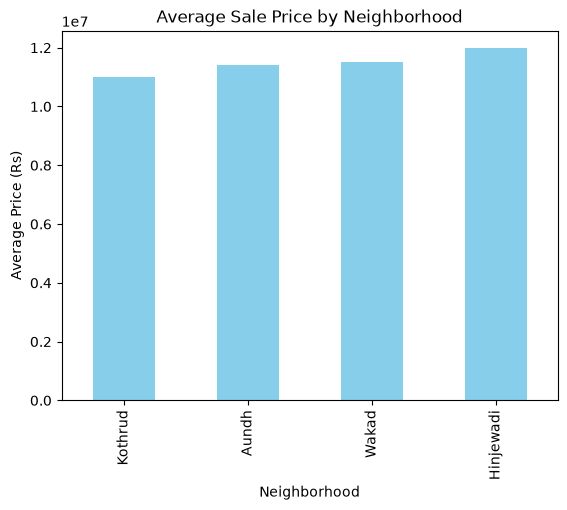

In [10]:
avg_by_neighborhood.plot(kind="bar", color="skyblue")
plt.title("Average Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average Price (Rs)")
plt.show()

In [11]:
df_encoded = pd.get_dummies(df, columns=["neighborhood", "property_type"], drop_first=True)
print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Shape after encoding: (250, 12)


,property_id,area_sqft,bedrooms,sale_price_rs,year_built,zone,area_type,neighborhood_Hinjewadi,neighborhood_Kothrud,neighborhood_Wakad,property_type_Plot,property_type_Villa
0,1,604,1,10898035,2020,West,Residential,False,False,True,False,True
1,2,2153,3,16490355,2003,West,Residential,False,False,False,False,True
2,3,2912,3,16767181,2021,Central,Residential,False,True,False,False,True
3,4,1239,2,8590920,1991,West,IT Corridor,True,False,False,False,False
4,5,2065,3,17276029,2008,West,Residential,False,False,False,False,False
